In [15]:
import math
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import matplotlib.pyplot as plt


# ============================================================
# DDPM BASELINE SOBRE CIFAR-10
#
# Adaptación directa del modelo usado para MNIST:
#
# MNIST:    [B, 1, 28, 28]
# CIFAR-10: [B, 3, 32, 32]
#
# ============================================================

# ============================================================
# 1. DISPOSITIVO
# ============================================================

In [16]:
def get_device():

    if torch.cuda.is_available():

        print(
            "Usando GPU:",
            torch.cuda.get_device_name(0)
        )

        return torch.device("cuda")

    else:

        print("Usando CPU")

        return torch.device("cpu")


device = get_device()

Usando GPU: Quadro RTX 6000


# ============================================================
# 2. DATOS: CIFAR-10
#
# CIFAR-10:
#
# 50 000 imágenes de entrenamiento
# 3 canales RGB
# 32 x 32 píxeles
#
# Normalizamos cada canal de [0,1] a aproximadamente [-1,1].
# ============================================================

In [17]:
transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])


dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=transform
)


BATCH_SIZE = 64


loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)


x0, labels = next(
    iter(loader)
)


print(
    "Shape de un batch:",
    x0.shape
)

print(
    "Labels:",
    labels[:10]
)

# Esperamos:
#
# torch.Size([64, 3, 32, 32])

Shape de un batch: torch.Size([64, 3, 32, 32])
Labels: tensor([4, 7, 7, 7, 4, 3, 8, 9, 0, 1])


# ============================================================
# 3. VISUALIZAR DATOS ORIGINALES
# ============================================================

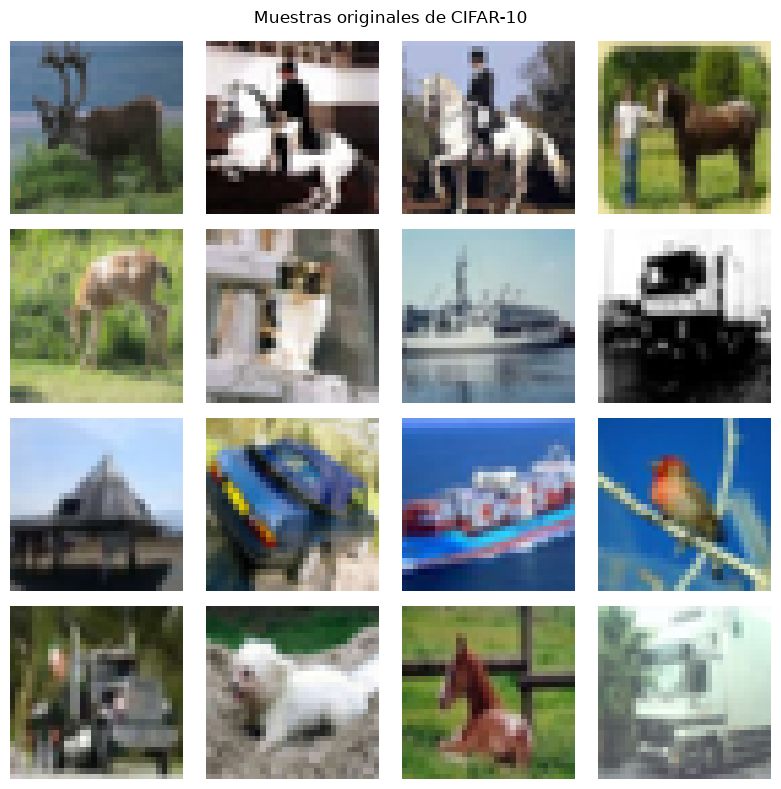

In [18]:
def tensor_to_rgb(image):

    """
    image:
        [3, H, W]

    Pasa de [-1,1] a [0,1]
    y de [C,H,W] a [H,W,C].
    """

    image = (
        image.detach()
        .cpu()
    )

    image = (
        image + 1
    ) / 2

    image = image.clamp(
        0,
        1
    )

    image = image.permute(
        1,
        2,
        0
    )

    return image


plt.figure(
    figsize=(8, 8)
)


for i in range(16):

    plt.subplot(
        4,
        4,
        i + 1
    )

    plt.imshow(
        tensor_to_rgb(
            x0[i]
        )
    )

    plt.axis("off")


plt.suptitle(
    "Muestras originales de CIFAR-10"
)

plt.tight_layout()

plt.show()


# ============================================================
# 4. SCHEDULE DE DIFUSIÓN
#
# Conservamos exactamente el mismo esquema usado con MNIST.
# ============================================================

In [19]:
T = 1000

beta_start = 1e-4
beta_end = 0.02


betas = torch.linspace(
    beta_start,
    beta_end,
    T,
    device=device
)


alphas = (
    1.0
    -
    betas
)


alpha_bars = torch.cumprod(
    alphas,
    dim=0
)


print(
    "beta inicial:",
    betas[0].item()
)

print(
    "beta final:",
    betas[-1].item()
)

print(
    "alpha_bar final:",
    alpha_bars[-1].item()
)


beta inicial: 9.999999747378752e-05
beta final: 0.019999999552965164
alpha_bar final: 4.035829260828905e-05


# ============================================================
# 5. PROCESO FORWARD
# ============================================================

In [20]:
def forward_diffusion_sample(
    x0,
    t
):

    """
    x0:
        [B, 3, 32, 32]

    t:
        [B]

    xt =
        sqrt(alpha_bar_t) x0
        +
        sqrt(1-alpha_bar_t) epsilon
    """

    noise = torch.randn_like(
        x0
    )


    alpha_bar_t = (
        alpha_bars[t]
    )


    alpha_bar_t = (
        alpha_bar_t[
            :,
            None,
            None,
            None
        ]
    )


    xt = (

        torch.sqrt(
            alpha_bar_t
        )
        *
        x0

        +

        torch.sqrt(
            1.0
            -
            alpha_bar_t
        )
        *
        noise
    )


    return xt, noise

# ============================================================
# 6. VISUALIZAR FORWARD
# ============================================================

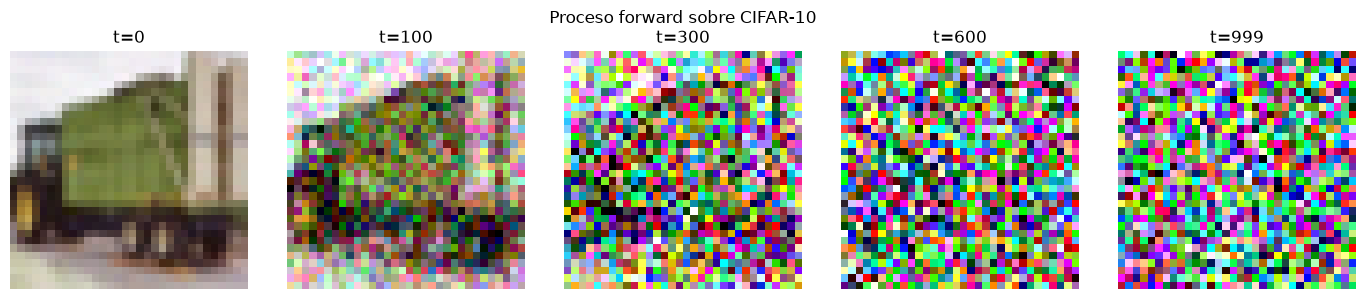

In [21]:
x0_test, _ = next(
    iter(loader)
)

x0_test = (
    x0_test[:1]
    .to(device)
)


times = [
    0,
    100,
    300,
    600,
    999
]


plt.figure(
    figsize=(14, 3)
)


for i, timestep in enumerate(
    times
):

    t = torch.tensor(
        [timestep],
        device=device
    )


    xt, _ = (
        forward_diffusion_sample(
            x0_test,
            t
        )
    )


    image = tensor_to_rgb(
        xt[0]
    )


    plt.subplot(
        1,
        len(times),
        i + 1
    )


    plt.imshow(
        image
    )


    plt.title(
        f"t={timestep}"
    )


    plt.axis(
        "off"
    )


plt.suptitle(
    "Proceso forward sobre CIFAR-10"
)

plt.tight_layout()

plt.show()

# ============================================================
# 7. TIME EMBEDDING
#
# Igual al modelo de MNIST.
# ============================================================

In [22]:
class SinusoidalTimeEmbedding(
    nn.Module
):

    def __init__(
        self,
        dim
    ):

        super().__init__()

        self.dim = dim


    def forward(
        self,
        t
    ):

        half_dim = (
            self.dim // 2
        )


        frequencies = (
            math.log(10000)
            /
            (
                half_dim - 1
            )
        )


        frequencies = torch.exp(

            torch.arange(
                half_dim,
                device=t.device
            )

            *

            -frequencies
        )


        angles = (

            t.float()[
                :,
                None
            ]

            *

            frequencies[
                None,
                :
            ]
        )


        embedding = torch.cat(

            [
                angles.sin(),
                angles.cos()
            ],

            dim=1
        )


        return embedding

# ============================================================
# 8. RESIDUAL BLOCK
#
# Igual al modelo de MNIST.
# ============================================================

In [23]:
class ResBlock(
    nn.Module
):

    def __init__(
        self,
        in_channels,
        out_channels,
        time_dim
    ):

        super().__init__()


        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )


        self.norm1 = nn.GroupNorm(
            8,
            out_channels
        )


        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )


        self.norm2 = nn.GroupNorm(
            8,
            out_channels
        )


        self.time_mlp = nn.Sequential(

            nn.SiLU(),

            nn.Linear(
                time_dim,
                out_channels
            )
        )


        if (
            in_channels
            !=
            out_channels
        ):

            self.residual = nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1
            )

        else:

            self.residual = (
                nn.Identity()
            )


    def forward(
        self,
        x,
        t_emb
    ):

        h = self.conv1(
            x
        )

        h = self.norm1(
            h
        )

        h = F.silu(
            h
        )


        time_information = (
            self.time_mlp(
                t_emb
            )
        )


        time_information = (
            time_information[
                :,
                :,
                None,
                None
            ]
        )


        h = (
            h
            +
            time_information
        )


        h = self.conv2(
            h
        )


        h = self.norm2(
            h
        )


        h = (
            h
            +
            self.residual(
                x
            )
        )


        return F.silu(
            h
        )

# ATTENTION

In [24]:
# ============================================================
# SELF-ATTENTION ESPACIAL
# ============================================================

class SelfAttentionBlock(nn.Module):

    def __init__(
        self,
        channels,
        num_heads=4
    ):

        super().__init__()

        self.norm = nn.GroupNorm(
            8,
            channels
        )

        self.attention = nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=num_heads,
            batch_first=True
        )


    def forward(self, x):

        # x: [B, C, H, W]

        residual = x

        x = self.norm(x)

        B, C, H, W = x.shape

        # [B, C, H, W] -> [B, H*W, C]
        x = x.flatten(2)
        x = x.transpose(1, 2)

        # Self-attention:
        # Q = K = V = x
        x_attended, _ = self.attention(
            x,
            x,
            x,
            need_weights=False
        )

        # [B, H*W, C] -> [B, C, H, W]
        x_attended = x_attended.transpose(
            1,
            2
        )

        x_attended = x_attended.reshape(
            B,
            C,
            H,
            W
        )

        # Conexión residual
        return residual + x_attended

In [25]:
# ============================================================
# U-NET RGB + SELF-ATTENTION
# ============================================================

class SimpleUNetAttention(nn.Module):

    def __init__(
        self,
        time_dim=64
    ):

        super().__init__()


        # ----------------------------------------------------
        # Embedding temporal
        # ----------------------------------------------------

        self.time_embedding = nn.Sequential(

            SinusoidalTimeEmbedding(
                time_dim
            ),

            nn.Linear(
                time_dim,
                time_dim
            ),

            nn.SiLU(),

            nn.Linear(
                time_dim,
                time_dim
            )
        )


        # ----------------------------------------------------
        # Entrada RGB
        # ----------------------------------------------------

        self.input_conv = nn.Conv2d(
            3,
            64,
            kernel_size=3,
            padding=1
        )


        # ----------------------------------------------------
        # Encoder
        # 32 x 32
        # ----------------------------------------------------

        self.block1 = ResBlock(
            64,
            64,
            time_dim
        )


        # 32 -> 16
        self.down1 = nn.Conv2d(
            64,
            128,
            kernel_size=4,
            stride=2,
            padding=1
        )


        self.block2 = ResBlock(
            128,
            128,
            time_dim
        )


        # 16 -> 8
        self.down2 = nn.Conv2d(
            128,
            256,
            kernel_size=4,
            stride=2,
            padding=1
        )


        # ----------------------------------------------------
        # Bottleneck
        # 8 x 8
        # ----------------------------------------------------

        self.middle = ResBlock(
            256,
            256,
            time_dim
        )


        # ----------------------------------------------------
        # Self-Attention
        # 8 x 8, 256 canales
        # ----------------------------------------------------

        self.attention = SelfAttentionBlock(
            channels=256,
            num_heads=4
        )


        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        # 8 -> 16
        self.up1 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=4,
            stride=2,
            padding=1
        )


        self.block3 = ResBlock(
            256,
            128,
            time_dim
        )


        # 16 -> 32
        self.up2 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=4,
            stride=2,
            padding=1
        )


        self.block4 = ResBlock(
            128,
            64,
            time_dim
        )


        # ----------------------------------------------------
        # Salida RGB
        # ----------------------------------------------------

        self.output_conv = nn.Conv2d(
            64,
            3,
            kernel_size=1
        )


    def forward(
        self,
        x,
        t
    ):

        # Embedding temporal
        t_emb = self.time_embedding(
            t
        )


        # Entrada
        x = self.input_conv(
            x
        )


        # Encoder
        skip1 = self.block1(
            x,
            t_emb
        )


        x = self.down1(
            skip1
        )


        skip2 = self.block2(
            x,
            t_emb
        )


        x = self.down2(
            skip2
        )


        # Bottleneck
        x = self.middle(
            x,
            t_emb
        )


        # Self-attention
        x = self.attention(
            x
        )


        # Decoder
        x = self.up1(
            x
        )


        x = torch.cat(
            [
                x,
                skip2
            ],
            dim=1
        )


        x = self.block3(
            x,
            t_emb
        )


        x = self.up2(
            x
        )


        x = torch.cat(
            [
                x,
                skip1
            ],
            dim=1
        )


        x = self.block4(
            x,
            t_emb
        )


        return self.output_conv(
            x
        )

# ============================================================
# 9. U-NET RGB
#
# CAMBIOS IMPORTANTES:
#
# entrada:
#     1 canal -> 3 canales
#
# salida:
#     1 canal -> 3 canales
#
# El resto se conserva.
# ============================================================

In [26]:
class SimpleUNet(
    nn.Module
):

    def __init__(
        self,
        time_dim=64
    ):

        super().__init__()


        # ----------------------------------------------------
        # Embedding temporal
        # ----------------------------------------------------

        self.time_embedding = (
            nn.Sequential(

                SinusoidalTimeEmbedding(
                    time_dim
                ),

                nn.Linear(
                    time_dim,
                    time_dim
                ),

                nn.SiLU(),

                nn.Linear(
                    time_dim,
                    time_dim
                )
            )
        )


        # ----------------------------------------------------
        # ENTRADA RGB
        #
        # CAMBIO:
        #
        # MNIST:
        #     1 -> 64
        #
        # CIFAR:
        #     3 -> 64
        # ----------------------------------------------------

        self.input_conv = nn.Conv2d(
            3,
            64,
            kernel_size=3,
            padding=1
        )


        # ----------------------------------------------------
        # Encoder
        # 32 x 32
        # ----------------------------------------------------

        self.block1 = ResBlock(
            64,
            64,
            time_dim
        )


        # 32 -> 16
        self.down1 = nn.Conv2d(
            64,
            128,
            kernel_size=4,
            stride=2,
            padding=1
        )


        self.block2 = ResBlock(
            128,
            128,
            time_dim
        )


        # 16 -> 8
        self.down2 = nn.Conv2d(
            128,
            256,
            kernel_size=4,
            stride=2,
            padding=1
        )


        # ----------------------------------------------------
        # Bottleneck
        # 8 x 8
        # ----------------------------------------------------

        self.middle = ResBlock(
            256,
            256,
            time_dim
        )


        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        # 8 -> 16
        self.up1 = (
            nn.ConvTranspose2d(
                256,
                128,
                kernel_size=4,
                stride=2,
                padding=1
            )
        )


        self.block3 = ResBlock(
            256,
            128,
            time_dim
        )


        # 16 -> 32
        self.up2 = (
            nn.ConvTranspose2d(
                128,
                64,
                kernel_size=4,
                stride=2,
                padding=1
            )
        )


        self.block4 = ResBlock(
            128,
            64,
            time_dim
        )


        # ----------------------------------------------------
        # SALIDA RGB
        #
        # CAMBIO:
        #
        # MNIST:
        #     64 -> 1
        #
        # CIFAR:
        #     64 -> 3
        #
        # La red predice ruido RGB.
        # ----------------------------------------------------

        self.output_conv = nn.Conv2d(
            64,
            3,
            kernel_size=1
        )


    def forward(
        self,
        x,
        t
    ):

        # Embedding temporal
        t_emb = (
            self.time_embedding(
                t
            )
        )


        # Entrada
        x = self.input_conv(
            x
        )


        # Encoder
        skip1 = self.block1(
            x,
            t_emb
        )


        x = self.down1(
            skip1
        )


        skip2 = self.block2(
            x,
            t_emb
        )


        x = self.down2(
            skip2
        )


        # Bottleneck
        x = self.middle(
            x,
            t_emb
        )


        # Decoder
        x = self.up1(
            x
        )


        x = torch.cat(
            [
                x,
                skip2
            ],
            dim=1
        )


        x = self.block3(
            x,
            t_emb
        )


        x = self.up2(
            x
        )


        x = torch.cat(
            [
                x,
                skip1
            ],
            dim=1
        )


        x = self.block4(
            x,
            t_emb
        )


        return self.output_conv(
            x
        )

# ============================================================
# 10. CREAR MODELO
# ============================================================

In [ ]:
model = SimpleUNetAttentionEMA().to(
    device
)

n_parameters = sum(
    p.numel()
    for p in model.parameters()
)


print(
    "Número de parámetros:",
    f"{n_parameters:,}"
)


# ============================================================
# 11. PRUEBA DE UNA PASADA
#
# Antes de entrenar verificamos:
#
# x0              [B,3,32,32]
# xt              [B,3,32,32]
# epsilon         [B,3,32,32]
# epsilon_theta   [B,3,32,32]
# ============================================================

x0_test, _ = next(
    iter(loader)
)

x0_test = x0_test.to(
    device
)


t_test = torch.randint(
    0,
    T,
    (x0_test.shape[0],),
    device=device
)


xt_test, noise_test = (
    forward_diffusion_sample(
        x0_test,
        t_test
    )
)


with torch.no_grad():

    predicted_noise_test = model(
        xt_test,
        t_test
    )


print(
    "x0:",
    x0_test.shape
)

print(
    "xt:",
    xt_test.shape
)

print(
    "Ruido real:",
    noise_test.shape
)

print(
    "Ruido predicho:",
    predicted_noise_test.shape
)


test_loss = F.mse_loss(
    predicted_noise_test,
    noise_test
)


print(
    "Loss antes de entrenar:",
    test_loss.item()
)

Número de parámetros: 3,773,123


x0: torch.Size([64, 3, 32, 32])
xt: torch.Size([64, 3, 32, 32])
Ruido real: torch.Size([64, 3, 32, 32])
Ruido predicho: torch.Size([64, 3, 32, 32])
Loss antes de entrenar: 1.1814137697219849


# ============================================================
# 12. ENTRENAMIENTO
#
# Conservamos inicialmente:
#
# Adam
# lr = 1e-4
# 50 épocas
# ============================================================

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)


EPOCHS = 50


epoch_losses = []


Path(
    "modelos"
).mkdir(
    exist_ok=True
)


Path("Img CIFAR10 Attention EMA").mkdir(
    exist_ok=True
)


for epoch in range(
    EPOCHS
):

    model.train()

    total_loss = 0.0


    for x0, _ in loader:

        x0 = x0.to(
            device,
            non_blocking=True
        )


        # Tiempo aleatorio para cada imagen
        t = torch.randint(
            0,
            T,
            (x0.shape[0],),
            device=device
        )


        # Forward
        xt, noise = (
            forward_diffusion_sample(
                x0,
                t
            )
        )


        # Predicción de ruido
        predicted_noise = model(
            xt,
            t
        )


        # MSE
        loss = F.mse_loss(
            predicted_noise,
            noise
        )


        optimizer.zero_grad()

        loss.backward()

        optimizer.step()


        total_loss += (
            loss.item()
        )


    average_loss = (
        total_loss
        /
        len(loader)
    )


    epoch_losses.append(
        average_loss
    )


    print(
        f"Época "
        f"{epoch + 1:2d}/"
        f"{EPOCHS} | "
        f"Pérdida promedio: "
        f"{average_loss:.6f}"
    )


    # --------------------------------------------------------
    # CHECKPOINT DE SEGURIDAD
    #
    # Sobrescribimos después de cada época.
    # Así no pierdes todo si se termina el job.
    # --------------------------------------------------------

    torch.save(

        model.state_dict(),

        "modelos/"
        "cifar10_diffusion_model_attention_ema.pt"
    )


print(
    "Entrenamiento terminado."
)

Época  1/50 | Pérdida promedio: 0.089667
Época  2/50 | Pérdida promedio: 0.047226
Época  3/50 | Pérdida promedio: 0.041886
Época  4/50 | Pérdida promedio: 0.039542
Época  5/50 | Pérdida promedio: 0.038261
Época  6/50 | Pérdida promedio: 0.037223
Época  7/50 | Pérdida promedio: 0.036288
Época  8/50 | Pérdida promedio: 0.035083
Época  9/50 | Pérdida promedio: 0.035476
Época 10/50 | Pérdida promedio: 0.034851
Época 11/50 | Pérdida promedio: 0.034443
Época 12/50 | Pérdida promedio: 0.034180
Época 13/50 | Pérdida promedio: 0.033856
Época 14/50 | Pérdida promedio: 0.033954
Época 15/50 | Pérdida promedio: 0.033870
Época 16/50 | Pérdida promedio: 0.033987
Época 17/50 | Pérdida promedio: 0.033358
Época 18/50 | Pérdida promedio: 0.032849
Época 19/50 | Pérdida promedio: 0.033179
Época 20/50 | Pérdida promedio: 0.033064
Época 21/50 | Pérdida promedio: 0.032953
Época 22/50 | Pérdida promedio: 0.033089
Época 23/50 | Pérdida promedio: 0.032852
Época 24/50 | Pérdida promedio: 0.033204
Época 25/50 | Pé

# ============================================================
# 13. CURVA DE LOSS
# ============================================================

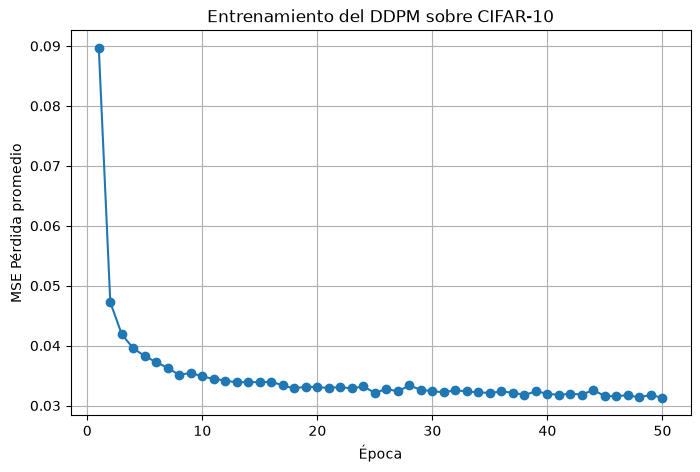

In [ ]:
plt.figure(
    figsize=(8, 5)
)


plt.plot(
    range(
        1,
        EPOCHS + 1
    ),
    epoch_losses,
    marker="o"
)


plt.xlabel(
    "Época"
)

plt.ylabel(
    "MSE Pérdida promedio"
)

plt.title(
    "Entrenamiento del DDPM sobre CIFAR-10"
)

plt.grid()


plt.savefig(
    "Img CIFAR10 Attention EMA/"
    "cifar10_training_loss_attention_ema.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

# ============================================================
# 14. RECARGAR MODELO
# ============================================================

In [ ]:
model = SimpleUNetAttentionEMA().to(
    device
)


model.load_state_dict(

    torch.load(
        "modelos/"
        "cifar10_diffusion_model_attention.pt",
        map_location=device,
        weights_only=True
    )
)


model.eval()


print(
    "Modelo CIFAR-10 cargado correctamente."
)

Modelo CIFAR-10 cargado correctamente.


# ============================================================
# 15. PROCESO REVERSE
#
# Mismo algoritmo usado en MNIST.
# ============================================================

In [32]:
@torch.no_grad()
def sample_reverse(
    model,
    n_samples=16
):

    model.eval()


    # --------------------------------------------------------
    # AHORA el ruido tiene 3 canales y resolución 32 x 32
    # --------------------------------------------------------

    x = torch.randn(
        n_samples,
        3,
        32,
        32,
        device=device
    )


    snapshots = {}


    save_times = [
        999,
        750,
        500,
        250,
        0
    ]


    for timestep in reversed(
        range(T)
    ):

        t = torch.full(
            (n_samples,),
            timestep,
            device=device,
            dtype=torch.long
        )


        # Predicción del ruido RGB
        predicted_noise = model(
            x,
            t
        )


        beta_t = betas[
            timestep
        ]


        alpha_t = alphas[
            timestep
        ]


        alpha_bar_t = (
            alpha_bars[
                timestep
            ]
        )


        # ----------------------------------------------------
        # Media del reverse
        # ----------------------------------------------------

        mean = (

            1
            /
            torch.sqrt(
                alpha_t
            )

        ) * (

            x

            -

            beta_t
            /
            torch.sqrt(
                1
                -
                alpha_bar_t
            )
            *
            predicted_noise
        )


        if timestep > 0:

            alpha_bar_previous = (
                alpha_bars[
                    timestep - 1
                ]
            )


            posterior_variance = (

                beta_t

                *

                (
                    1
                    -
                    alpha_bar_previous
                )

                /

                (
                    1
                    -
                    alpha_bar_t
                )
            )


            z = torch.randn_like(
                x
            )


            x = (

                mean

                +

                torch.sqrt(
                    posterior_variance
                )
                *
                z
            )


        else:

            x = mean


        if timestep in save_times:

            snapshots[
                timestep
            ] = (

                x.detach()
                .cpu()
            )


    return x, snapshots

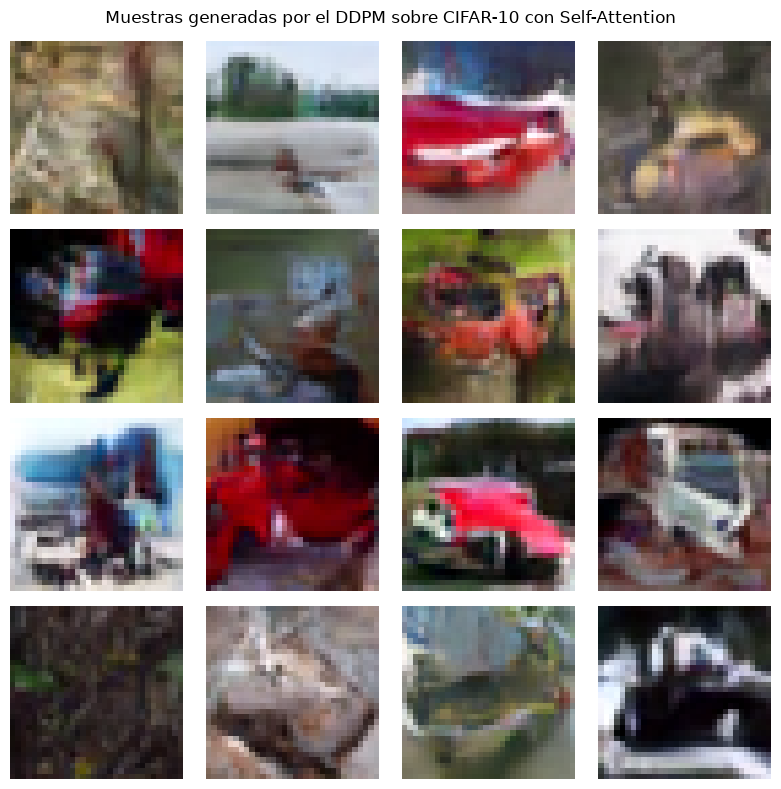

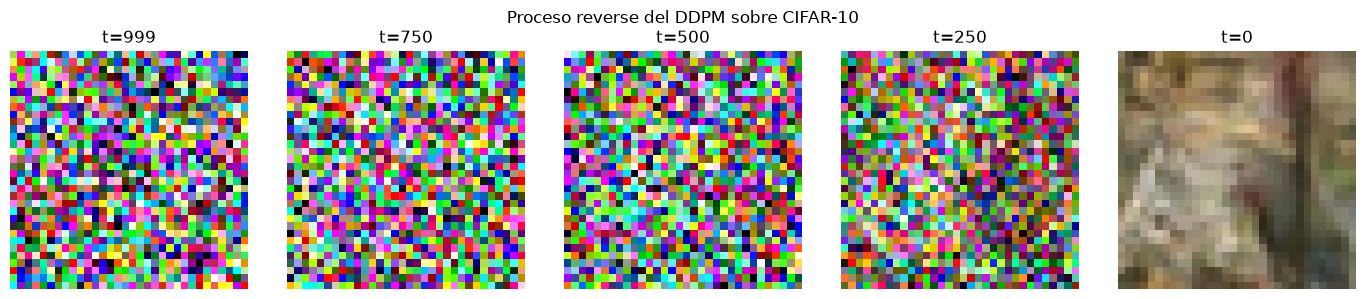

Proceso CIFAR-10 terminado.


In [ ]:

torch.manual_seed(
    42
)


if torch.cuda.is_available():

    torch.cuda.manual_seed_all(
        42
    )


generated_images, snapshots = (
    sample_reverse(
        model,
        n_samples=16
    )
)


# ============================================================
# 17. VISUALIZAR IMÁGENES GENERADAS
# ============================================================

plt.figure(
    figsize=(8, 8)
)


for i in range(16):

    plt.subplot(
        4,
        4,
        i + 1
    )


    image = tensor_to_rgb(
        generated_images[i]
    )


    plt.imshow(
        image
    )


    plt.axis(
        "off"
    )


plt.suptitle(
    "Muestras generadas por el DDPM sobre CIFAR-10 con Self-Attention"
)


plt.tight_layout()


plt.savefig(
    "Img CIFAR10 Attention/"
    "generated_cifar10_attention.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# 18. VISUALIZAR UNA TRAYECTORIA REVERSE
# ============================================================

times_to_show = [
    999,
    750,
    500,
    250,
    0
]


plt.figure(
    figsize=(14, 3)
)


for i, timestep in enumerate(
    times_to_show
):

    image = snapshots[
        timestep
    ][0]


    image = tensor_to_rgb(
        image
    )


    plt.subplot(
        1,
        len(times_to_show),
        i + 1
    )


    plt.imshow(
        image
    )


    plt.title(
        f"t={timestep}"
    )


    plt.axis(
        "off"
    )


plt.suptitle(
    "Proceso reverse del DDPM sobre CIFAR-10"
)


plt.tight_layout()


plt.savefig(
    "Img CIFAR10 Attention EMA/"
    "reverse_process_cifar10_attention_ema.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print(
    "Proceso CIFAR-10 terminado."
)

Reverse con diagnóstico de Score

In [34]:
# ============================================================
# DIAGNÓSTICO DEL SCORE DURANTE EL REVERSE DE CIFAR-10
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

Path("Img CIFAR10").mkdir(exist_ok=True)

model.eval()


# Tiempos que queremos observar
save_times = [
    999,
    750,
    500,
    250,
    50,
    0
]


@torch.no_grad()
def reverse_with_score_diagnostics(
    model,
    n_samples=1
):

    model.eval()

    # Empezamos desde ruido gaussiano RGB
    x = torch.randn(
        n_samples,
        3,
        32,
        32,
        device=device
    )

    diagnostics = []

    # Para analizar cómo cambia la magnitud del score
    score_history = []


    # ========================================================
    # PROCESO REVERSE
    # ========================================================

    for timestep in reversed(range(T)):

        t_tensor = torch.full(
            (n_samples,),
            timestep,
            device=device,
            dtype=torch.long
        )


        beta_t = betas[timestep]

        alpha_t = alphas[timestep]

        alpha_bar_t = alpha_bars[timestep]


        # ====================================================
        # 1. LA U-NET PREDICE EL RUIDO RGB
        # ====================================================

        epsilon_pred = model(
            x,
            t_tensor
        )


        # ====================================================
        # 2. SCORE
        #
        # s_theta(x_t,t)
        #
        #          - epsilon_theta(x_t,t)
        # = --------------------------------
        #          sqrt(1 - alpha_bar_t)
        #
        # Shape:
        #
        # [B, 3, 32, 32]
        # ====================================================

        score_pred = (
            -epsilon_pred
            /
            torch.sqrt(
                1.0 - alpha_bar_t
            )
        )


        # ====================================================
        # 3. ESTIMACIÓN INSTANTÁNEA DE x_0
        # ====================================================

        x0_hat = (
            x
            -
            torch.sqrt(
                1.0 - alpha_bar_t
            )
            *
            epsilon_pred
        ) / torch.sqrt(
            alpha_bar_t
        )


        # ====================================================
        # 4. MAGNITUD DEL SCORE POR PÍXEL
        #
        # Cada píxel tiene:
        #
        # (s_R, s_G, s_B)
        #
        # Tomamos:
        #
        # sqrt(s_R² + s_G² + s_B²)
        # ====================================================

        score_magnitude = torch.linalg.vector_norm(
            score_pred,
            dim=1
        )


        mean_score_magnitude = (
            score_magnitude
            .mean()
            .item()
        )


        score_history.append(
            (
                timestep,
                mean_score_magnitude
            )
        )


        # ====================================================
        # 5. GUARDAR DIAGNÓSTICOS
        # ====================================================

        if timestep in save_times:

            diagnostics.append({

                "t":
                    timestep,

                "xt":
                    x.detach()
                    .cpu()
                    .clone(),

                "epsilon_pred":
                    epsilon_pred.detach()
                    .cpu()
                    .clone(),

                "score_pred":
                    score_pred.detach()
                    .cpu()
                    .clone(),

                "x0_hat":
                    x0_hat.detach()
                    .cpu()
                    .clone()
            })


        # ====================================================
        # 6. PASO REVERSE DDPM
        # ====================================================

        mean = (
            1.0
            /
            torch.sqrt(
                alpha_t
            )
        ) * (
            x
            -
            beta_t
            /
            torch.sqrt(
                1.0 - alpha_bar_t
            )
            *
            epsilon_pred
        )


        if timestep > 0:

            alpha_bar_previous = (
                alpha_bars[
                    timestep - 1
                ]
            )


            posterior_variance = (
                beta_t
                *
                (
                    1.0
                    -
                    alpha_bar_previous
                )
                /
                (
                    1.0
                    -
                    alpha_bar_t
                )
            )


            z = torch.randn_like(x)


            x = (
                mean
                +
                torch.sqrt(
                    posterior_variance
                )
                *
                z
            )


        else:

            x = mean


    diagnostics = sorted(
        diagnostics,
        key=lambda d: d["t"],
        reverse=True
    )


    return (
        x.detach().cpu(),
        diagnostics,
        score_history
    )

In [35]:
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


final_image, diagnostics, score_history = (
    reverse_with_score_diagnostics(
        model,
        n_samples=1
    )
)


print(
    "Tiempos guardados:",
    [d["t"] for d in diagnostics]
)

Tiempos guardados: [999, 750, 500, 250, 50, 0]


Figura principal

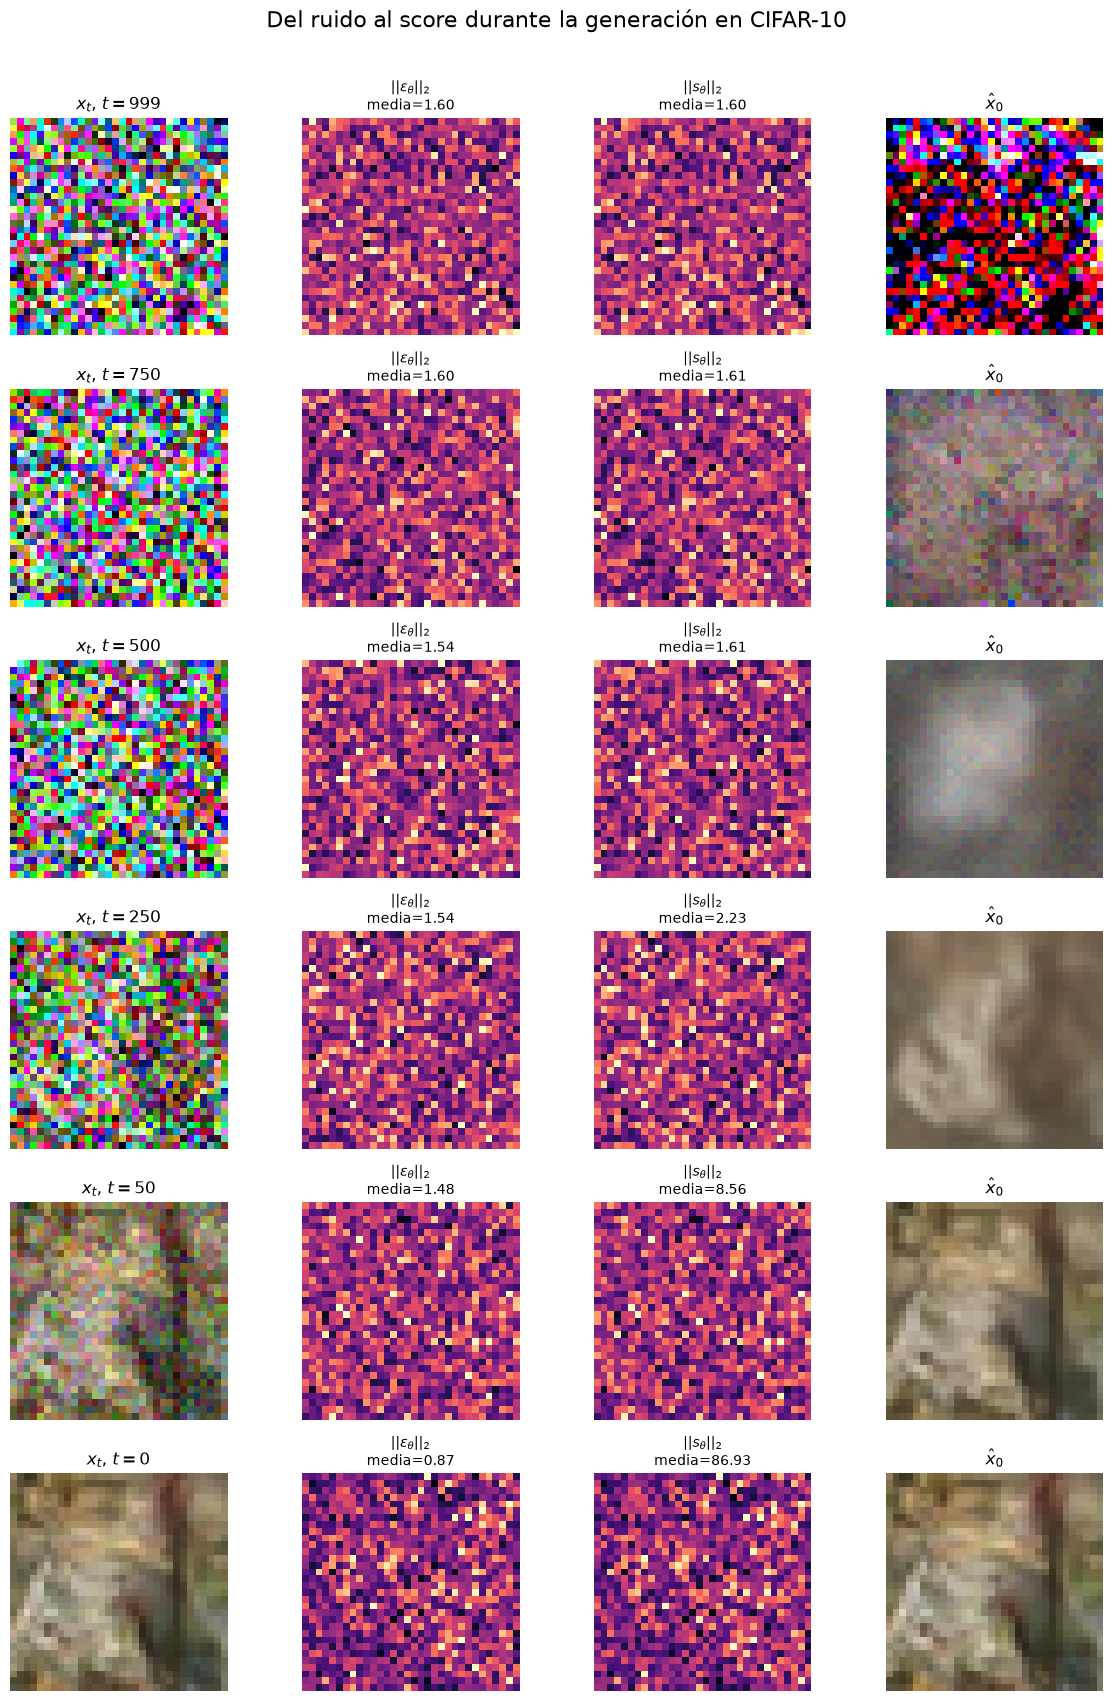

In [ ]:
# ============================================================
# FUNCIONES DE VISUALIZACIÓN
# ============================================================

def rgb_display(tensor):

    """
    Tensor [3,H,W] en escala aproximadamente [-1,1]
    -> imagen RGB [0,1].
    """

    image = (
        tensor
        .squeeze(0)
        .detach()
        .cpu()
    )

    image = (
        image + 1
    ) / 2

    image = image.clamp(
        0,
        1
    )

    image = image.permute(
        1,
        2,
        0
    )

    return image.numpy()



def magnitude_map(tensor):

    """
    tensor:
        [1,3,H,W]

    Devuelve:
        sqrt(R² + G² + B²)
    """

    tensor = (
        tensor
        .squeeze(0)
    )

    magnitude = torch.linalg.vector_norm(
        tensor,
        dim=0
    )

    return magnitude.numpy()



def show_magnitude(
    ax,
    tensor,
    title
):

    mag = magnitude_map(
        tensor
    )

    # Escala robusta para no dejar que unos pocos
    # valores extremos dominen toda la figura
    vmax = np.percentile(
        mag,
        99
    )

    if vmax < 1e-8:
        vmax = 1.0

    im = ax.imshow(
        mag,
        cmap="magma",
        vmin=0,
        vmax=vmax
    )

    ax.set_title(
        title,
        fontsize=10
    )

    ax.axis("off")

    return im


# ============================================================
# FIGURA
# ============================================================

n_rows = len(
    diagnostics
)

fig, axes = plt.subplots(
    n_rows,
    4,
    figsize=(
        12,
        2.8 * n_rows
    )
)


for i, result in enumerate(
    diagnostics
):

    timestep = result["t"]


    # --------------------------------------------------------
    # 1. x_t
    # --------------------------------------------------------

    axes[i, 0].imshow(
        rgb_display(
            result["xt"]
        )
    )

    axes[i, 0].set_title(
        rf"$x_t$, $t={timestep}$"
    )

    axes[i, 0].axis(
        "off"
    )


    # --------------------------------------------------------
    # 2. Magnitud del ruido predicho
    # --------------------------------------------------------

    eps_mag = magnitude_map(
        result["epsilon_pred"]
    )

    mean_eps = eps_mag.mean()


    show_magnitude(
        axes[i, 1],
        result["epsilon_pred"],
        rf"$||\epsilon_\theta||_2$"
        + "\n"
        + rf"media={mean_eps:.2f}"
    )


    # --------------------------------------------------------
    # 3. Magnitud del score
    # --------------------------------------------------------

    score_mag = magnitude_map(
        result["score_pred"]
    )

    mean_score = score_mag.mean()


    show_magnitude(
        axes[i, 2],
        result["score_pred"],
        rf"$||s_\theta||_2$"
        + "\n"
        + rf"media={mean_score:.2f}"
    )


    # --------------------------------------------------------
    # 4. x0_hat
    # --------------------------------------------------------

    x0_hat_display = (
        result["x0_hat"]
        .clamp(
            -1,
            1
        )
    )


    axes[i, 3].imshow(
        rgb_display(
            x0_hat_display
        )
    )


    axes[i, 3].set_title(
        r"$\hat{x}_0$"
    )


    axes[i, 3].axis(
        "off"
    )


plt.suptitle(
    "Del ruido al score durante la generación en CIFAR-10",
    fontsize=16,
    y=1.01
)


plt.tight_layout()


plt.savefig(
    "Img CIFAR10 Attention EMA/"
    "cifar10_score_diagnostics_ema.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

Magnitud media del score a lo largo del reverse

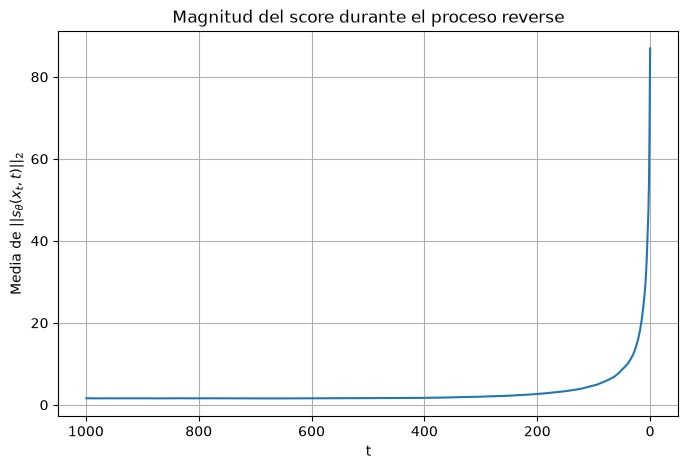

In [ ]:
# ============================================================
# MAGNITUD MEDIA DEL SCORE A LO LARGO DEL REVERSE
# ============================================================

timesteps = np.array([
    t
    for t, score in score_history
])


mean_scores = np.array([
    score
    for t, score in score_history
])


plt.figure(
    figsize=(8, 5)
)


plt.plot(
    timesteps,
    mean_scores
)


plt.xlabel(
    "t"
)


plt.ylabel(
    r"Media de $||s_\theta(x_t,t)||_2$"
)


plt.title(
    "Magnitud del score durante el proceso reverse"
)


# El reverse va de 999 hacia 0
plt.gca().invert_xaxis()


plt.grid()


plt.savefig(
    "Img CIFAR10 Attention EMA/"
    "cifar10_score_magnitude_ema.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

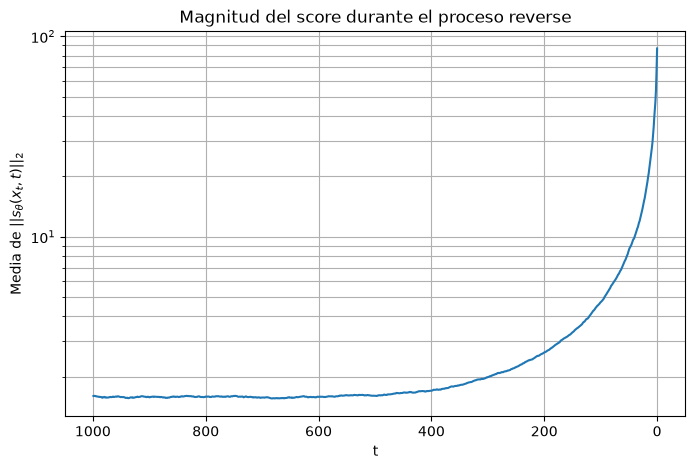

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    timesteps,
    mean_scores
)

plt.xlabel("t")

plt.ylabel(
    r"Media de $||s_\theta(x_t,t)||_2$"
)

plt.title(
    "Magnitud del score durante el proceso reverse"
)

plt.yscale("log")

plt.gca().invert_xaxis()

plt.grid(
    True,
    which="both"
)

plt.show()

Componentes RGB del score en t = 250

NameError: name 'xt_display' is not defined

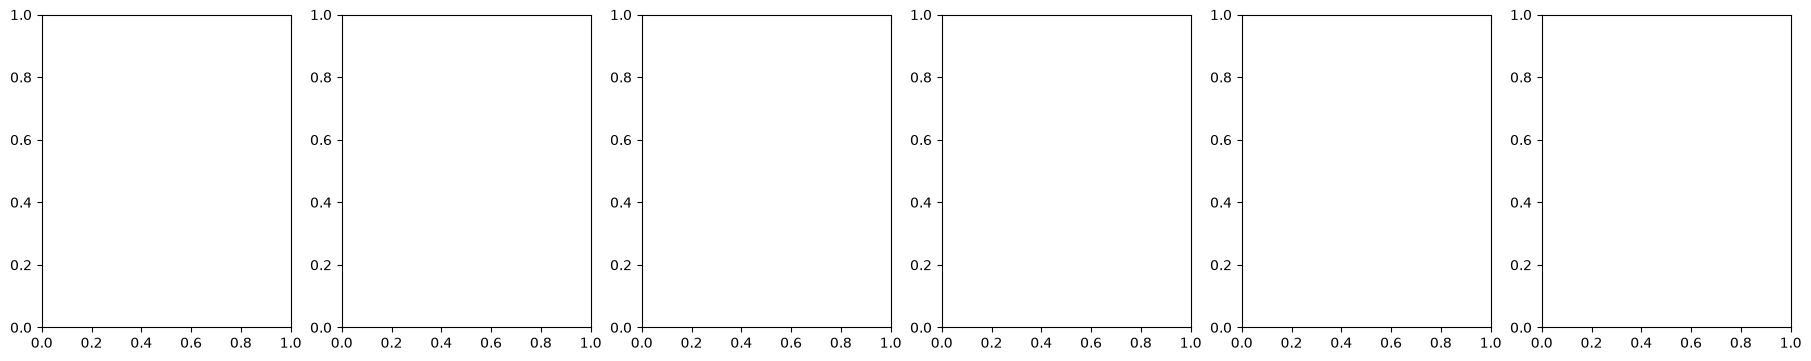

In [ ]:
# ============================================================
# 6. FIGURA
# ============================================================

fig, axes = plt.subplots(
    1,
    6,
    figsize=(18, 3.5),
    constrained_layout=True
)


# x_t
axes[0].imshow(xt_display)
axes[0].set_title(
    rf"$x_t$, $t={t_selected}$"
)
axes[0].axis("off")


# Score R
im = axes[1].imshow(
    score_R,
    cmap="coolwarm",
    vmin=-vmax,
    vmax=vmax
)
axes[1].set_title(r"$s_R$")
axes[1].axis("off")


# Score G
axes[2].imshow(
    score_G,
    cmap="coolwarm",
    vmin=-vmax,
    vmax=vmax
)
axes[2].set_title(r"$s_G$")
axes[2].axis("off")


# Score B
axes[3].imshow(
    score_B,
    cmap="coolwarm",
    vmin=-vmax,
    vmax=vmax
)
axes[3].set_title(r"$s_B$")
axes[3].axis("off")


# Magnitud total
axes[4].imshow(
    score_magnitude,
    cmap="magma"
)
axes[4].set_title(
    r"$\|s_\theta\|_2$"
)
axes[4].axis("off")


# x0_hat
axes[5].imshow(
    x0_display
)
axes[5].set_title(
    r"$\hat{x}_0$"
)
axes[5].axis("off")


# Colorbar compartida para R, G y B
cbar = fig.colorbar(
    im,
    ax=axes[1:4],
    fraction=0.025,
    pad=0.02
)

cbar.set_label(
    "Componente del score",
    labelpad=8
)


fig.suptitle(
    rf"Componentes RGB del score en $t={t_selected}$",
    fontsize=16
)


plt.savefig(
    "Img CIFAR10 Attention EMA/"
    "cifar10_score_rgb_components_t250_ema.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()